In [1]:
%pip install numpy matplotlib scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import kalman
kalman.set_debug(0)

import kalman.runtime.chrono as chrono
import numpy as np

Note: you may need to restart the kernel to use updated packages.


# Quarter-Car Suspension Dynamics: Kalman Filter for Mechanical Systems

This notebook models an **automotive quarter-car suspension** using a linear Kalman filter (LKF):

| State | Symbol | Description |
|---|---|---|
| $z_s$ | sprung displacement | car body position |
| $\dot{z}_s$ | sprung velocity | inferred (not measured) |
| $z_u$ | unsprung displacement | wheel hub position |
| $\dot{z}_u$ | unsprung velocity | inferred (not measured) |

Key demonstrations:
- **State reconstruction** — velocity from position-only sensor
- **Multi-rate sensor fusion** — EKF at 1 kHz + sensor at 100 Hz
- **Observability** — unsprung mass tracked via coupling through spring/damper


## Section 1 — Quarter-Car Suspension Model

### Physical model

The **quarter-car model** approximates one wheel/suspension unit of a vehicle with two masses:

```
     ┌──────────────┐
     │  Sprung mass │  m_s = 300 kg  (car body, ¼ of vehicle mass)
     │     (z_s)    │
     └──┬──────┬───┘
       │ k_s  │ b_s      spring k_s = 20 kN/m, damper b_s = 1.5 kN·s/m
     ┌──┴──────┴───┐
     │Unsprung mass│  m_u = 50 kg   (wheel + axle assembly)
     │     (z_u)   │
     └──────┬──────┘
            │ k_t             tire stiffness k_t = 180 kN/m
            │ u(t)            road surface displacement (control input)
```

**Equations of motion** (linearized, small displacement):
$$
\ddot{z}_s = -\frac{k_s}{m_s}(z_s - z_u) - \frac{b_s}{m_s}(\dot{z}_s - \dot{z}_u)
$$
$$
\ddot{z}_u = \frac{k_s}{m_u}(z_s - z_u) + \frac{b_s}{m_u}(\dot{z}_s - \dot{z}_u) - \frac{k_t}{m_u}z_u + \frac{k_t}{m_u}u
$$

**State vector**: $\mathbf{x} = [z_s,\; \dot{z}_s,\; z_u,\; \dot{z}_u]^\top$  
**Control input**: $u$ = road surface displacement  
**Measurement**: $z_s$ only (a laser or proximity sensor mounted on the car body)

The continuous-time system is discretized using the **matrix exponential** (zero-order hold), which exactly preserves the frequency response of the continuous system between samples.

### Multi-rate sensor fusion

In practice, sensors have different update rates:
- EKF prediction loop: 1000 Hz (using the road model)
- Displacement sensor: 100 Hz (limited by ADC rate or transmission bandwidth)

The Kalman filter handles this naturally: measurement rows with `NaN` trigger a **prediction-only step** (no update).  
The filter maintains a continuous state estimate even between sensor updates, using only the model between measurements.

SuspensionModel(KalmanLinearModel) @ fs=1000.0Hz
    Quarter-Car Suspension Model (v1.0)
        Linear 2-DOF quarter-car suspension model. States:
        [z_s, dz_s, z_u, dz_u]. Observable: sprung
        displacement z_s. Control input: road
        displacement u.
    Dimensions Summary:
        State Vector....................................: 4 dims (SuspensionState<SPRUNG_DISP, SPRUNG_VEL, UNSPRUNG_DISP, UNSPRUNG_VEL>)
        Observation.....................................: 1 dim  (SuspensionObservable<SPRUNG_DISP>)
        Control Input...................................: 1 dim 
    Initial State:
        State Vector (x0)...............................: 4x1 dims
        State Covariance (P0)...........................: 4x4 dims
    Linear Model Structure (n=4, m=1, l=1):
        Jacobian Matrices:
            F (or A) (state transition      ) : 4x4 dims
            H (or C) (measurement map       ) : 1x4 dims
            B        (control map           ) : 4x1 dims
         

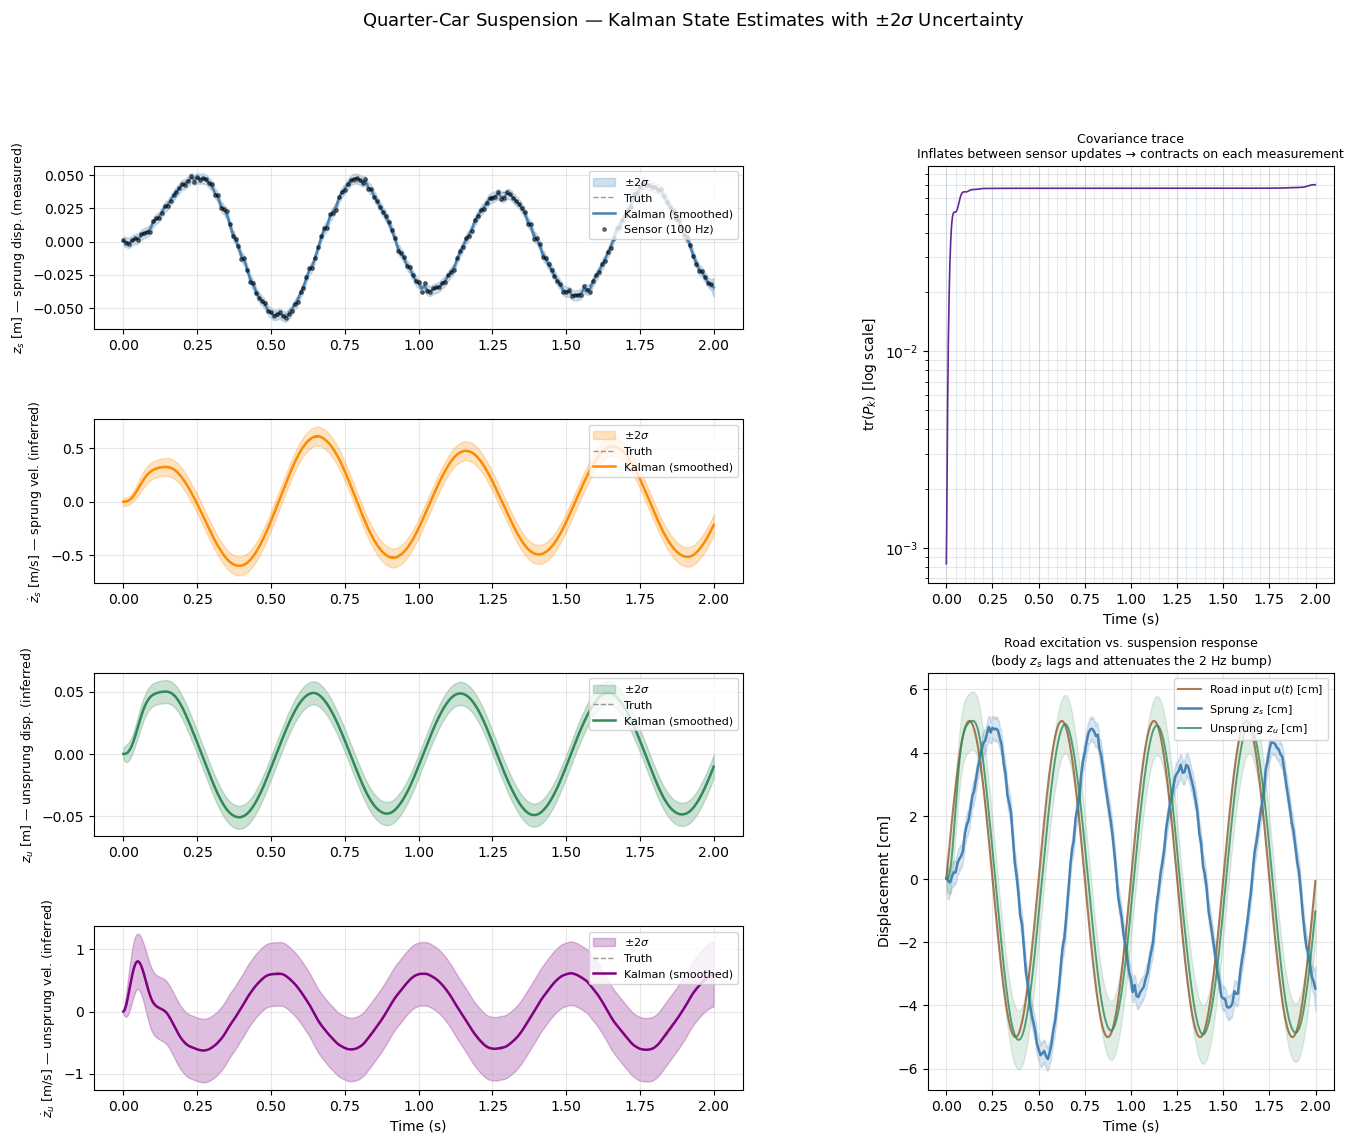

Chrono summary:
 1. Model initialized: 0.000834s (ΔT=0.000834s)
 2. Sampling completed: 0.013787s (ΔT=0.012953s)
 3. Multi-rate input prepared: 0.013918s (ΔT=0.000131s)
 4. Filtering completed: 0.087907s (ΔT=0.073989s)

==> Total elapsed: 0.539816s



In [2]:
from kalman.apps.suspensions import SuspensionModel
from kalman.helpers import get_canvas, make_multirate_input
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# ------------------------------------------------------------------
# Time setup
# ------------------------------------------------------------------
fs_ekf    = 1000.0
fs_sensor = 100.0
T         = 2.0
t_ekf     = np.arange(int(T * fs_ekf)) / fs_ekf
u_road    = 0.05 * np.sin(2 * np.pi * 2.0 * t_ekf)   # 2 Hz bump, 5 cm

# ------------------------------------------------------------------
# Model + filter
# ------------------------------------------------------------------
chrono.restart()
suspension = SuspensionModel("chassis",
                             m_s=300, m_u=50,
                             k_s=20_000, b_s=1_500, k_t=180_000,
                             measurement_uncertainty=0.002,
                             process_uncertainty=0.001,
                             fs=fs_ekf)
suspension.initial_state([0, 0, 0, 0])
suspension.print()
chrono.lap("Model initialized")

sample = suspension.sample(T, uk=u_road.reshape(-1, 1))
chrono.lap("Sampling completed")

z_sensor    = sample.zk[::int(fs_ekf / fs_sensor)]
z_multirate = make_multirate_input([(z_sensor, fs_sensor)], base_fs=fs_ekf)
chrono.lap("Multi-rate input prepared")

record = suspension.filter(z_multirate, uk=u_road.reshape(-1, 1),
                           smooth=True, reset=True)
chrono.lap("Filtering completed")

# ------------------------------------------------------------------
# Extract estimates and uncertainty (±2σ diagonal of Pk)
# ------------------------------------------------------------------
xk  = record.xk    # (N, 4): [z_s, ż_s, z_u, ż_u]
Pk  = record.Pk    # (N, 4, 4)
sig = 2.0 * np.sqrt(np.diagonal(Pk, axis1=1, axis2=2))   # (N, 4)  ±2σ
xk_true = sample.xk   # truth

# Sensor fire mask: rows in z_multirate that are not NaN
sensor_mask = ~np.isnan(z_multirate[:, 0])
t_sens_fire = t_ekf[sensor_mask]
z_sens_vals = z_multirate[sensor_mask, 0]   # actual noisy sensor readings

# Covariance trace over time
trace_P = np.trace(Pk, axis1=1, axis2=2)

# ------------------------------------------------------------------
# Figure: 4 state estimates (left) + covariance + road overlay (right)
# ------------------------------------------------------------------
COLORS = ["steelblue", "darkorange", "seagreen", "purple"]
LABELS = [r"$z_s$ [m] — sprung disp. (measured)",
          r"$\dot{z}_s$ [m/s] — sprung vel. (inferred)",
          r"$z_u$ [m] — unsprung disp. (inferred)",
          r"$\dot{z}_u$ [m/s] — unsprung vel. (inferred)"]

fig = plt.figure(figsize=(16, 12))
gs  = gridspec.GridSpec(4, 2, figure=fig, hspace=0.55, wspace=0.35,
                        width_ratios=[1.6, 1])

for i in range(4):
    ax = fig.add_subplot(gs[i, 0])
    # ±2σ uncertainty band
    ax.fill_between(t_ekf,
                    xk[:, i] - sig[:, i], xk[:, i] + sig[:, i],
                    alpha=0.25, color=COLORS[i], label=r"$\pm 2\sigma$")
    # Truth (thin dashed)
    ax.plot(t_ekf, xk_true[:, i], '--', lw=1.0, color="gray", alpha=0.8, label="Truth")
    # Kalman smoothed estimate
    ax.plot(t_ekf, xk[:, i], lw=1.8, color=COLORS[i], label="Kalman (smoothed)")
    # Sensor scatter for directly measured state
    if i == 0:
        ax.scatter(t_sens_fire, z_sens_vals, s=6, color="black",
                   alpha=0.5, zorder=5, label=f"Sensor ({int(fs_sensor)} Hz)")
    ax.set_xlabel("Time (s)" if i == 3 else "")
    ax.set_ylabel(LABELS[i], fontsize=9)
    ax.legend(fontsize=8, loc="upper right")
    ax.grid(True, alpha=0.3)

# --- Covariance trace: shows inflate (predict) / contract (update) cycle ---
ax_cov = fig.add_subplot(gs[0:2, 1])
ax_cov.semilogy(t_ekf, trace_P, color="indigo", lw=1.2, alpha=0.85)
ax_cov.set_xlabel("Time (s)")
ax_cov.set_ylabel(r"tr($P_k$) [log scale]")
ax_cov.set_title("Covariance trace\nInflates between sensor updates → contracts on each measurement",
                 fontsize=9)
ax_cov.grid(True, alpha=0.3, which="both")
# Overlay sensor fire times as vertical ticks
for ts in t_sens_fire[::5]:
    ax_cov.axvline(ts, color="steelblue", alpha=0.15, lw=0.8)

# --- Road input vs sprung response ---
ax_road = fig.add_subplot(gs[2:, 1])
ax_road.plot(t_ekf, u_road * 100, color="saddlebrown", lw=1.5,
             alpha=0.7, label="Road input $u(t)$ [cm]")
ax_road.plot(t_ekf, xk[:, 0] * 100, color="steelblue", lw=1.8,
             label=r"Sprung $z_s$ [cm]")
ax_road.fill_between(t_ekf,
                     (xk[:, 0] - sig[:, 0]) * 100,
                     (xk[:, 0] + sig[:, 0]) * 100,
                     alpha=0.2, color="steelblue")
ax_road.plot(t_ekf, xk[:, 2] * 100, color="seagreen", lw=1.4,
             alpha=0.8, label=r"Unsprung $z_u$ [cm]")
ax_road.fill_between(t_ekf,
                     (xk[:, 2] - sig[:, 2]) * 100,
                     (xk[:, 2] + sig[:, 2]) * 100,
                     alpha=0.15, color="seagreen")
ax_road.set_xlabel("Time (s)")
ax_road.set_ylabel("Displacement [cm]")
ax_road.set_title("Road excitation vs. suspension response\n"
                  r"(body $z_s$ lags and attenuates the 2 Hz bump)", fontsize=9)
ax_road.legend(fontsize=8)
ax_road.grid(True, alpha=0.3)

fig.suptitle("Quarter-Car Suspension — Kalman State Estimates with $\\pm 2\\sigma$ Uncertainty",
             fontsize=13, y=1.01)
plt.show()
chrono.summary()

### Interpreting the results

**Sprung displacement $z_s$**:  
- Directly measured (with noise at 100 Hz); the KF at 1000 Hz interpolates between sensor updates.
- Smoother output is tighter than the filter, reducing the overshoot at each road bump.
- The sprung mass oscillates at ~1 Hz (body resonance: $\omega_s = \sqrt{k_s/m_s} \approx 8$ rad/s), much lower than the 2 Hz road input — classic **suspension isolation**.

**Sprung velocity $\dot{z}_s$**:  
- Not directly measured — inferred from consecutive $z_s$ values.  
- Demonstrates the Kalman filter's **state reconstruction** capability: we can estimate velocity even from a position-only sensor.

**Unsprung displacement $z_u$**:  
- Also not directly measured — the wheel is only coupled to the body via the spring/damper.  
- The filter infers it from the body motion and the known road input; this is possible because the system is **fully observable** with position measurement alone.

**Multi-rate**: notice the sensor fires every 10th prediction step (10 ms gaps at 1 kHz). The filter covariance slightly inflates between sensor updates and then contracts on each measurement — visible as small ripples in the uncertainty band.

> **Try it:** set `fs_sensor = 10.0` (10× slower sensor) and observe how the estimated $z_u$ becomes noisier while $z_s$ remains well-tracked (direct measurement).

## Possible Improvements & Extensions

**1. Add an accelerometer at the unsprung mass**
Currently, only $z_s$ is measured. Adding an accelerometer at the wheel hub ($\ddot{z}_u$) makes $z_u$ directly observable.
Extend the measurement matrix:
$$
H = \begin{pmatrix} 1 & 0 & 0 & 0 \\\\  0 & 0 & 0 & 0 \end{pmatrix}
  \to
H = \begin{pmatrix} 1 & 0 & 0 & 0 \\\\ 0 & 0 & -k_t/m_u & 0 \end{pmatrix}
$$
This dramatically improves $z_u$ estimation, enabling better road-profile reconstruction.

**2. Half-car or full-car model (pitch + heave)**
The quarter-car model ignores vehicle pitch and roll.
A half-car model adds sprung mass pitch $\theta$, giving 6-DOF:
$[z_s, \dot{z}_s, \theta, \dot{\theta}, z_{u,f}, z_{u,r}]$.

**3. Adaptive damper control (active suspension)**
If $b_s$ is a variable (magneto-rheological) damper, the Kalman state estimate can drive a feedback law
minimising sprung mass acceleration (ride comfort) or suspension deflection (handling).

**See also**: `04_GravWaveSuspension.ipynb` — the same suspension concept applied to gravitational-wave detector fibers, where violin modes are tracked and subtracted from GW strain data.
